## Background 

A new Premier League season has begun, and that means millions of fans are gearing up to play Fantasy Premier League (FPL) again, which is a fantasy football game where users select 15 players from the Premier League whilst balancing a fixed budget, earning points based on real-world match performance. 

After exploring introductory optimisation problems in first-year, I found out that FPL actually has neat parallels to portfolio construction and optimisation in finance: selecting assets from a large universe, subject to multiple constraints to maximise expected returns. There are a few similarities in both being a constrained optimisation problem:  

- A manager selecting a range of **players** from a large universe of choices -> An investor selecting a range of **assets** from a large universe of choices. 
- A manager maximising expected **points** subject to strict in-game constraints -> An investor maximising expected **returns** subject to real-life financial constraints. 

The constraints themselves have some similarities,  like these three examples:

1. An FPL constraint like the fixed £100m budget is similar to the maximum available capital that investors have. 
2. No more than three players from the same team are allowed, introducing a diversification constraint similar to portfolio construction.
3. Neither problem is deterministic: future player performance is uncertain (injuries, drops in form, harder matchdays ahead), just like the uncertainty of asset returns (associated risk, market downturns).

The final point raises a key question: how should a manager balance expected performance against uncertainty? This project applies portfolio optimisation techniques to FPL team selection, aiming to test whether a systematic, risk-aware method produces better teams than greedy player picking. 

## Question

"Can portfolio optimisation techniques improve FPL team selection compared to simple greedy-picking heuristics?"

## Modern Portfolio Theory and FPL

Modern Portfolio Theory (MPT), developed by Harry Markowitz in 1952, provides a framework for constructing portfolios by considering expected return, risk, and how assets move together through their covariances.

In this project, we take MPT's use for financial assets and apply it to our FPL team. Instead of selecting assets to maximise expected returns, we select players to maximise expected points. However, a player's individual value should not be considered in isolation; uncertainty of points and how their performance impacts other players in the team must also be considered. 

This leads to the central idea behind the project (and MPT in general): The best team is not necessarily the team containing the 15 players with the highest predicted points. That is actually known as 'greedy selection,' which forms the baseline of this project. Instead, portfolio optimisation aims to combine players that achieve the best trade-off between expected points and risk. 

Consider three Arsenal defenders in our team. Arguably, they have the strongest defence in the league, so they may give strong expected points. However, this is not guaranteed. They could concede, or one may get a red card; as a result, all of them lose out together. Selecting players whose performances are less correlated can therefore provide greater diversification and potentially reduce overall team risk. This is why FPL forces players to not choose more than three players from the same team. 

In financial portfolio optimisation, this trade-off can be expressed mathematically as objective functions: either maximising expected return for a given level of risk, or minimising risk for a given level of return. We apply the same principle to FPL by seeking teams that maximise expected points while factoring in player volatility and covariance.

The following sections formalise these ideas and translate them into an FPL optimisation problem.

### Expected Return

In MPT, each asset has an expected return $\mu_i$, usually written as:

$$
\mu_i = \mathbb{E}[R_i]
$$

where $R_i$ is the return of asset $i$. 

For FPL, we can replace return with player points, denoted by $P_i$. If we estimate that a player will score 6 points in the next gameweek, then their expected points are:

$$
\mu_i = \mathbb{E}[P_i] = 6
$$

For a portfolio, expected return is simply the weighted sum of the individual expected returns:

$$
\mathbb{E}[R_p] = \sum_{i=1}^{n} w_i\mu_i
$$

where $w_i$ is the weight of asset $i$ in the portfolio (the proportion of the total portfolio invested in that asset).

A key distinction between this and our FPL model is that in a traditional portfolio, you choose how much to invest in that asset, so $w_i$ is a continuous value. However, in FPL you either select a player or you don't, which is a binary selection instead. This is expanded upon as we build the optimisation problem itself. The intuition remains the same for FPL: expected points of a team depend on the expected points of the players selected. However, expected points are predictions, not guarantees. A player expected to score 6 points could score 2, 10, or 0. This uncertainty leads us to risk.

### Volatility / Risk

In MPT, individual asset risk is measured by the variance of their returns, or its square root, the standard deviation. For FPL, we can apply the same idea for individual player risk: 

$$
\sigma_i^2 = \operatorname{Var}(P_i)
$$

$$
\sigma_i = \sqrt{\operatorname{Var}(P_i)}
$$

where $\sigma_i$ is the individual player risk. To explain how portfolio risk works, consider two players A and B: 

- **Player A:** 2, 8, 2, 8, 2, 8
- **Player B:** 5, 6, 5, 6, 5, 6

The average points are similar, but Player A's points variation is much greater than Player B, who has a more consistent spread. For this reason, a manager would prefer players that provide smaller, predictable returns like B rather than larger, volatile ones like A.

However, portfolio risk as a whole is not simply the sum of individual player risks. This is where covariance and correlation are introduced. 

### Covariance and Correlation

So far, we have calculated variances of assets, but this only tells us how returns move individually - not together. That's where covariance comes in. For the FPL scenario, covariance, $\operatorname{Cov}(P_i,P_j)$ measures the tendency of two players' points to move together across gameweeks.

Using the previous example, positive covariance means that Player A's points being above average implies the same for Player B. Negative covariance means their performances tend to move in opposite directions. We can also standardise covariance, also known as correlation:

$$
\rho_{ij}
=
\frac{\operatorname{Cov}(P_i,P_j)}
{\sigma_i\sigma_j}
$$

with values between -1 and 1.

The FPL interpretation is that two defenders from the same team may have $\rho_{ij}$ close to 1 because a clean sheet can benefit both players simultaneously. Meanwhile, players from completely different teams and positions may have $\rho_{ij}$ closer to 0 instead. Note that we don't assume these relationships - it is simply estimated from historical FPL data.

This is another key insight from MPT: diversification works because portfolio assets do not necessarily move perfectly together. The same principle potentially applies to an FPL team. 

### Portfolio Risk

Now that we have defined the key components of portfolio theory (expected return, individual risk, covariance between assets), we can combine these ideas to calculate the overall risk of a portfolio.

We start from the portfolio variance. By definition of variance in terms of covariance, we have:

$$
\sigma_p^2
=
\sum_{i=1}^{n}\sum_{j=1}^{n}
w_i w_j \operatorname{Cov}(P_i,P_j)
$$

This says to take every possible pair of assets, see how they move together (covariance), and weigh that relationship depending on how much of each asset you hold ($w_iw_j$). 

The double sum does this for every possible pair of assets, including when $i = j$, which is just $Cov(P_i,P_i) = Var(P_i)$. This is useful for the following covariance matrix that we also define:

$$
\Sigma =
\begin{bmatrix}
\operatorname{Cov}(P_1,P_1) & \operatorname{Cov}(P_1,P_2) & \cdots & \operatorname{Cov}(P_1,P_n) \\
\operatorname{Cov}(P_2,P_1) & \operatorname{Cov}(P_2,P_2) & \cdots & \operatorname{Cov}(P_2,P_n) \\
\vdots & \vdots & \ddots & \vdots \\
\operatorname{Cov}(P_n,P_1) & \operatorname{Cov}(P_n,P_2) & \cdots & \operatorname{Cov}(P_n,P_n)
\end{bmatrix}
$$

This is an $n * n$ matrix containing every possible relationship between assets. Note how the diagonals contain individual variances (individual volatility per player), whilst the non-diagonals contain pairwise covariances (how players move together). So to summarise, the covariance matrix sums up individual risks and relationships between risks. 

Next, we define the vector of portfolio weights:

$$
\mathbf{w}
=
\begin{bmatrix}
w_1 \\
w_2 \\
\vdots \\
w_n
\end{bmatrix}.
$$

This is what was described in expected return, this time in vector form. Now we have $\mathbf{w}$ (what you hold), $\Sigma$ (how everything behaves), and $\sigma_p^2$ (how risky the resulting portfolio is).  

Consider the simplest example: the two-player case. The possible combinations are $(i,j) = (1,1), (1,2), (2,1), (2,2)$. Therefore, applying the portfolio variance formula gives:

$$
\sigma_p^2
=
w_1^2\operatorname{Cov}(P_1,P_1)
+
w_1w_2\operatorname{Cov}(P_1,P_2)
+
w_2w_1\operatorname{Cov}(P_2,P_1)
+
w_2^2\operatorname{Cov}(P_2,P_2).
$$

Using the following covariance properties (variance and symmetry): 

$$\operatorname{Cov}(P_i,P_i)=\operatorname{Var}(P_i)$$ and $$\operatorname{Cov}(P_1,P_2)=\operatorname{Cov}(P_2,P_1)$$

we obtain:

$$
\sigma_p^2
=
w_1^2\operatorname{Var}(P_1)
+
w_2^2\operatorname{Var}(P_2)
+
2w_1w_2\operatorname{Cov}(P_1,P_2).
$$

The same calculation extends to any number of assets. 

Therefore, the double sum can be written compactly in matrix form as:

$$
\sigma_p^2
=
\mathbf{w}^{\top}\Sigma\mathbf{w}
$$

and portfolio volatility is:

$$
\sigma_p
=
\sqrt{\mathbf{w}^{\top}\Sigma\mathbf{w}}
.
$$

The distinction in FPL is that we replace portfolio weights $\mathbf{w}$ with a binary selection vector $\mathbf{x}$, where $x_i = 1$ if player $i$ is selected and $x_i = 0$ otherwise. The asset covariance matrix $\Sigma$ becomes the covariance matrix of player points. The formula becomes:

$$
\sigma_{\text{team}}^2 = \mathbf{x}^\top\Sigma\mathbf{x}
$$

### Squad vs. Starting XI

So far, $\mathbf{x}$ has represented the full 15-player squad. However, only 11 of those players actually start and score points each gameweek; the remaining 4 sit on the bench. To capture this, we introduce a second binary variable:

$$
y_i =
\begin{cases}
1, & \text{if player } i \text{ starts the gameweek},\\
0, & \text{otherwise}.
\end{cases}
$$

A player can only start if they are already in the squad, so the two variables are linked by:

$$
y_i \leq x_i \qquad \forall i.
$$

This prevents a logical contradiction: if $x_i = 0$ but $y_i = 1$, a player is in the starting XI despite not even being in the 15-man squad - the constraint rules this out. 

Exactly 11 players start each gameweek:

$$
\sum_{i=1}^{n} y_i = 11.
$$

Since expected points and risk are only realised by the starting XI, portfolio risk and expected points should be calculated using $\mathbf{y}$, not $\mathbf{x}$: 

$$
\mathbb{E}[P_{\text{XI}}] = \mathbf{y}^{\top}\boldsymbol{\mu}, \qquad \sigma_{\text{XI}}^2 = \mathbf{y}^{\top}\Sigma\mathbf{y}.
$$

Important note that this project deliberately excludes Bench Boost (the chip that scores all 15 players in a given gameweek), as well as other chips like Triple Captain (triples captain points), Wild Card (unlimited, free permanent transfers) and Free Hit (unlimited free transfers for one gameweek), since they are not used every week. The addition of chips are definitely something worth looking at should I wish to develop this project further, but for now the scope remains relatively minimal.

Squad selection ($\mathbf{x}$) and starting XI selection ($\mathbf{y}$) are optimised sequentially rather than jointly: the squad is chosen first, then the strongest XI is selected from within it. A joint optimisation would likely find a better combined outcome, since it wouldn't be constrained by a squad chosen without knowledge of the eventual XI split, but sequential optimisation keeps the project clearly explainable within a second-year scope, rather than adding complexity that stalls progress for a first attempt at this kind of problem.

Going back to team variance, this means it now has two components, similarly to portfolio variance:

1. Individual volatility (diagonal terms): $\sum_{i=1}^{n} y_i \operatorname{Var}(P_i)$ - how much each starting player's points fluctuate around their average.

2. Co-movement (off-diagonal terms): $\sum_{i \neq j} y_i y_j \operatorname{Cov}(P_i, P_j)$ - how much the starting players' points move together.

If all 11 starting players are highly correlated (e.g., all from strong teams), their points tend to move together, and team variance is high. Conversely, if selected players have low or negative correlations, the team variance is lower for the same expected points.

This is the quantitative case for diversification: selecting players whose performance correlates less will reduce overall team risk.

### The Return–Risk Trade-off

MPT now presents us with two competing objectives:

1. Maximise expected points
2. Minimise portfolio risk

Note that both objectives do not necessarily produce the same team: a team containing more top performers may have a higher expected score but also greater uncertainty. Another team might sacrifice some expected points in exchange for a lower portfolio variance.

Now that we have these two objectives, let's construct an objective function for the first one. The key idea is to combine the two quantities already derived.

Expected portfolio return (in vector form):

$$
\mathbb{E}[R_p]
=
\mathbf{w}^{\top}\boldsymbol{\mu}
$$

Portfolio variance (risk):

$$
\sigma_p^2
=
\mathbf{w}^{\top}\Sigma\mathbf{w}
$$

As mentioned before, we don't necessarily want to maximise one expression while ignoring the other; we want some balance between both. MPT balances these by maximising the difference between risk and reward, with an additional constant $\lambda$ acting as a conversion parameter between both objectives: 

$$
\max_{\mathbf{w}}
\quad
\mathbf{w}^{\top}\boldsymbol{\mu}
-
\lambda\mathbf{w}^{\top}\Sigma\mathbf{w}.
$$

Here, $\lambda\geq0$ controls the risk-return trade-off. In other words, it determines how heavy the optimiser penalises variance: 

- If $\lambda = 0$, then risk is completely ignored and we solely focus on maximising expected points. 
- If $\lambda$ is small, risk is lightly penalised, so expected return is still prioritised.
- If $\lambda$ is high, risk is highly penalised, so the optimiser is willing to sacrifice expected points for a lower-risk team.

For FPL, we replace the portfolio weights $\mathbf{w}$ with the starting-XI selection vector $\mathbf{y}$ (not the squad vector $\mathbf{x}$, since only starting players realise points and risk, as established above):

$$
\mathbb{E}[P_{\text{XI}}]
=
\mathbf{y}^{\top}\boldsymbol{\mu}
$$

and

$$
\sigma_{\text{XI}}^2
=
\mathbf{y}^{\top}\Sigma\mathbf{y}.
$$

Therefore, the FPL mean-variance objective becomes:

$$
\max_{\mathbf{y}}
\quad
\mathbf{y}^{\top}\boldsymbol{\mu}
-
\lambda\mathbf{y}^{\top}\Sigma\mathbf{y}
$$

subject to the FPL constraints (including $y_i \leq x_i$ and $\sum y_i = 11$). Intuitively this makes no difference to MPT itself: just a notation switch.  

Now the FPL problem is more than choosing players with the highest predicted points; the optimiser now considers how the players work together as a portfolio.

### Sharpe Ratio

A key performance metric in evaluating portfolio performance is the Sharpe ratio, which measures excess return relative to a risk-free rate against overall volatility:

$$
S = \frac{R_p-R_f}{\sigma_p}
$$

For FPL, we omit the risk-free rate as there is no obvious equivalent. Hence this simplifies to:

$$
S_{\text{FPL}} \approx \frac{P_p}{\sigma_p}
$$

This can be interpreted as points generated per unit of portfolio risk.

It gives us another way of comparing teams. A team with slightly fewer expected points could still be attractive if it achieves those points with substantially lower risk.

### Efficient Frontier

The efficient frontier in MPT represents the set of portfolios offering the best possible expected return for each level of risk. Applying this to FPL, imagine generating many different valid teams: some have high expected points but high risk, while others have low expected points with lower risk. The efficient teams are those for which there is no alternative team that:

- has higher expected points for the same level of risk, or
- has lower risk for the same expected points.

Plotting these teams graphically gives us the efficient frontier. This gives a more conclusive way of thinking about the final optimisation problem. Instead of assuming just one optimal FPL team, we can investigate the trade-off between expected points and portfolio risk before seeing how the optimal team changes with our tolerance for risk. Now we begin to formulate the FPL problem itself.


## FPL Problem Formulation

With the portfolio theory framework established, we can now translate the FPL selection problem into a formal optimisation problem.

Suppose there are $n$ available players. For each player $i$, we define a binary decision variable:

$$
x_i =
\begin{cases}
1, & \text{if player } i \text{ is selected},\\
0, & \text{otherwise}.
\end{cases}
$$

The vector

$$
\mathbf{x}=(x_1,x_2,\ldots,x_n)^\top
$$

therefore represents the composition of the FPL squad.

As established in the previous section, we also define a starting-XI vector $\mathbf{y}=(y_1,y_2,\ldots,y_n)^\top$, linked to $\mathbf{x}$ by $y_i \leq x_i$ and $\sum_{i=1}^{n} y_i = 11$.

Each player has their own price $c_i$, position, club, and estimated performance characteristics. The optimisation problem is to determine the values of $x_i$ (and subsequently $y_i$) that produce the best possible squad and starting XI that simultaneously satisfy the rules of the game.

### FPL Constraints

#### Budget constraint

Let $c_i$ denote the price of player $i$. The total squad cost cannot exceed the available budget $B$:

$$
\sum_{i=1}^{n}c_i x_i\leq B
$$

For the standard FPL game,

$$
B=£100\text{m}.
$$

#### Squad size

An FPL squad must contain exactly 15 players:

$$
\sum_{i=1}^{n}x_i=15
$$

#### Position constraints

Let $G_i,D_i,M_i,F_i$ be indicator variables taking the value 1 when player $i$ is respectively a goalkeeper, defender, midfielder, or forward.

The squad must contain exactly two goalkeepers:

$$
\sum_{i=1}^{n}G_i x_i=2
$$

five defenders:

$$
\sum_{i=1}^{n}D_i x_i=5
$$

five midfielders:

$$
\sum_{i=1}^{n}M_i x_i=5
$$

and three forwards:

$$
\sum_{i=1}^{n}F_i x_i=3.
$$

#### Club constraint

An FPL squad can contain no more than three players from the same Premier League club. Let $C_{ik}=1$ if player $i$ belongs to club $k$, and 0 otherwise. Then:

$$
\sum_{i=1}^{n}C_{ik}x_i\leq3
\qquad \forall k.
$$

Finally, each player is either selected or not selected:

$$
x_i\in\{0,1\}
\qquad \forall i.
$$

Together, these constraints define the feasible set of FPL squads.

#### Starting XI constraints

A player can only start if they are in the squad:

$$
y_i \leq x_i \qquad \forall i = 1, ..., n.
$$

Exactly 11 players start each gameweek:

$$
\sum_{i=1}^{n} y_i = 11.
$$

$$
y_i \in \{0,1\} \qquad \forall i = 1, ..., n.
$$

Together, these constraints define the feasible set of FPL squads and starting XIs.

### Optimisation Objectives

With the feasible set established, the next question is what exactly constitutes an "optimal" team.

Rather than assuming there is one universally optimal definition, this project considers three increasingly sophisticated approaches.

#### Objective 1: Greedy Selection

The simplest approach is a greedy heuristic: players are ranked by a performance measure (predicted points or points per million), then selected sequentially subject to FPL constraints.

This represents the intuitive approach of repeatedly asking: which player gives me the most value from the remaining options? However, greedy selection does not necessarily produce the globally optimal squad, as locally attractive choices can prevent better overall combinations from being constructed.

This provides a benchmark against which the optimisation-based approaches can be tested.

#### Objective 2: Mean-Variance Optimisation

The first portfolio-based objective follows MPT by balancing expected points against portfolio risk. Since only the starting XI realises points and risk, this objective is optimised over $\mathbf{y}$, subject to the full constraint set (including $y_i \leq x_i$, which links the XI back to a valid squad):

$$
\max_{\mathbf{y}}
\quad
\boldsymbol{\mu}^{\top}\mathbf{y}
-
\lambda\mathbf{y}^{\top}\Sigma\mathbf{y}
$$

subject to the FPL constraints above, where $\lambda \geq 0$ controls the trade-off between expected points and risk.

#### Objective 3: Balanced Optimisation

The third approach also uses expected points and risk, but notice how both variables are on different scales and units: variance is more likely to dominate expected points since it's a squared term, therefore its numbers are larger. In Objective 2, this issue was controlled by $\lambda$: not only did it control the trade-off between expected points and risk, but it scaled the variance term in the objective function. 

For this objective, we normalise both expected points and risk to a dimensionless scale with interval $[0,1]$.

For expected points:

$$
\tilde{\mu}_p
=
\frac{\mu_p-\mu_{\min}}
{\mu_{\max}-\mu_{\min}}
$$

and for portfolio variance:

$$
\tilde{\sigma}_p^2
=
\frac{\sigma_p^2-\sigma_{\min}^2}
{\sigma_{\max}^2-\sigma_{\min}^2}.
$$

The two normalised quantities can then be combined using:

$$
\max_{\mathbf{y}}
\quad
\alpha\tilde{\mu}_p
-
(1-\alpha)\tilde{\sigma}_p^2
$$

where:

$$
0\leq\alpha\leq1.
$$

Here, $\alpha$ directly controls the relative importance of expected points and risk:

- $\alpha=1$: maximise expected points only.
- $\alpha=0.5$: give equal weight to expected points and risk.
- $\alpha=0$: minimise risk only.

## Estimating the Model Parameters

The optimisation itself depends on estimating three parameters from historical FPL data:

1. Expected points $\mu_i$ for each player: using recent form, fixture difficulty, and player statistics.
2. Volatility $\sigma_i$ for each player: from the standard deviation of historical gameweek points.
3. Covariance matrix $\Sigma$: from historical correlations between player points.

From this, the empirical question is whether these portfolio-informed objectives produce better FPL teams than the greedy baseline. We now start to estimate these parameters.

### Load and Prepare FPL Data 

First, we load raw FPL data from the 25/26 season from an FPL Github repo. The initial number of columns was 105, but we reduced it to 21 columns, as they were the most relevant ones for the optimisation. Two columns in particular, 'element_type' and 'team' had numbers representing positions and club names respectively. I transformed these columns into readable positions (GK/DEF/MID/FWD) and club names to ensure better readability. The first five players of the dataframe are shown below, with readable club/position names. 

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# load 25/26 FPL data
players_url = 'https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/master/data/2025-26/players_raw.csv'
fixtures_url = 'https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/master/data/2025-26/fixtures.csv'
teams_url = 'https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/master/data/2025-26/teams.csv'

players_df = pd.read_csv(players_url) 
fixtures_df = pd.read_csv(fixtures_url)
teams_df = pd.read_csv(teams_url)

# keep essential optimisation columns 
essential_cols = [
    'id', 'first_name', 'second_name', 'web_name',
    'element_type', 'team',
    'now_cost', 'total_points', 'points_per_game', 'event_points', 'minutes',
    'form', 'ict_index', 'expected_goals', 'expected_goals_conceded',
    'expected_assists', 'clean_sheets', 'assists', 'goals_scored', 'starts', 'status'
]

players_df = players_df[essential_cols].copy()

# Map position codes to position names
position_map = {1: 'GK', 2: 'DEF', 3: 'MID', 4: 'FWD'}
players_df['position'] = players_df['element_type'].map(position_map)

# Map team id to club name
team_id_to_name = dict(zip(teams_df['id'], teams_df['name'])) # pairs 'id' and 'name' -> converts to dict 
players_df['club'] = players_df['team'].map(team_id_to_name) # maps old 'id' to a readable club name

# keep readable columns
players_df = players_df.drop(['element_type', 'team'], axis=1)

print(f"Data summary:", f"Players: {len(players_df)}, " f"Missing values: {players_df.isnull().sum().sum()}")
print(f"First 5 players:")
print(players_df[['web_name', 'position', 'club', 'now_cost', 'total_points']].head())

Data summary: Players: 841, Missing values: 0
First 5 players:
       web_name position     club  now_cost  total_points
0          Raya       GK  Arsenal        62           162
1  Arrizabalaga       GK  Arsenal        40             2
2          Hein       GK  Arsenal        40             0
3       Setford       GK  Arsenal        39             0
4       Gabriel      DEF  Arsenal        73           209


### Active Players

We clean our dataset even further by removing players that contribute to very little minutes across the whole season like reserve players, academy players, players with long-term injuries, etc. To do this, we use a for loop to cycle through some minute thresholds. 

The threshold I believe was enough for the active pool of players was 450 minutes (5 full 90s across a 38-game season). This reduces the initial playerbase of 841 into a neat 400 players to work with. This wasn't a data-driven choice but a practically arbitrary one. FPL users pick players that are active and consistently in the starting XI, let alone the first team; therefore, the inclusion of players making sporadic appearances across the season (and no minutes at all) is practically unnecessary. 

The greatest cut off is observed when 300+ players were omitted in shifting the threshold from 0 to 1, effectively clearing deadwood across all 20 teams. The following cutoffs are incrementally smaller each time, but 450 minutes was a resonable choice by me to ensure players that start/play regularly are the only players considered. Conveniently, there were exactly 400 players beyond this threshold, making it more appealing to use. 

In [2]:
minutes_thresholds = [0, 1, 90, 270, 450, 900]

for threshold in minutes_thresholds:
    subset = players_df[players_df['minutes'] >= threshold]
    print(f"Minutes >= {threshold}: {len(subset)} players")

active_players = players_df[players_df['minutes'] >= 450].copy()
print(f"\nActive pool: {len(active_players)} players")
print(active_players.groupby('position').size())

Minutes >= 0: 841 players
Minutes >= 1: 537 players
Minutes >= 90: 474 players
Minutes >= 270: 429 players
Minutes >= 450: 400 players
Minutes >= 900: 339 players

Active pool: 400 players
position
DEF    147
FWD     44
GK      28
MID    181
dtype: int64


### Greedy Baseline Squad

Now we build the greedy baseline squad. First we use a 'value' as a metric for points per game per £1m spent, as a way to measure player effectiveness. 

When initally creasing the squad, I ran into a constant error where forwards were not being selected at all. The reason being was that the solver didn't account for player positions: It picked 2 top value GKs, 5 top value defenders, 5 top value midfielders, but when it came to forwards, the budget had been swallowed up and it was impossible to buy even the cheapest ones. 

To fix this, I had to create a function that computed the minimum cost for remaining positions. In other words, the solver asks "If choose this player, can I afford to fill in remaining positions with their cheapest valid combinations?" before each player pick. That way, all positions are accounted for. The reserve budget function has three parameters, all different data structures:

1. `remaining_reqs` - a **dictionary** showing remaining positions and how many for each 
2. `players_pool` - the full `active_players` **data frame**
3. `already_selected_ids` - a **list** of player IDs that can't be picked again 

In [3]:
# greedy baseline

# value (PPG per £1m spent)
active_players['value'] = active_players['points_per_game'] / (active_players['now_cost'] / 10)

# function to compute min cost for remaining positions
def reserve_budget_check(remaining_reqs, players_pool, already_selected_ids): 
    total_min_cost = 0
    club_counts = {}
    
    # Count clubs in already-selected players
    for player_id in already_selected_ids:
        player = players_pool[players_pool['id'] == player_id].iloc[0]
        club = player['club']
        club_counts[club] = club_counts.get(club, 0) + 1
    
    for position, count_needed in remaining_reqs.items():
        # Get eligible players for this position (sorted by cost ascending = cheapest first)
        eligible = players_pool[
            (players_pool['position'] == position) &
            (~players_pool['id'].isin(already_selected_ids))
        ].sort_values('now_cost', ascending=True)
        
        filled = 0
        temp_club_counts = club_counts.copy()
        
        for _, player in eligible.iterrows():
            if filled == count_needed:
                break
            club = player['club']
            if temp_club_counts.get(club, 0) < 3:
                total_min_cost += player['now_cost']
                temp_club_counts[club] = temp_club_counts.get(club, 0) + 1
                filled += 1
        
        if filled < count_needed:
            # Can't fill this position even with cheapest players
            return float('inf')
    
    return total_min_cost

# Step 3: Build greedy squad
def build_greedy_squad(players_pool, budget=100.0):
    position_requirements = {'GK': 2, 'DEF': 5, 'MID': 5, 'FWD': 3}
    selected_ids = []
    selected_rows = []
    club_counts = {}
    remaining_budget = budget * 10  # now_cost is in tenths of a million
    
    for position, count_needed in position_requirements.items():
        eligible = players_pool[
            (players_pool['position'] == position) &
            (~players_pool['id'].isin(selected_ids))
        ].sort_values('value', ascending=False)
        
        filled_this_position = 0
        
        for _, player in eligible.iterrows():
            if filled_this_position == count_needed:
                break
            
            club = player['club']
            cost = player['now_cost']
            
            # Club limit check
            if club_counts.get(club, 0) >= 3:
                continue
            
            # Budget check for this pick alone
            if cost > remaining_budget:
                continue
            
            # Reserve-budget check: after this pick, can we still afford
            # the cheapest path to fill everything still outstanding?
            position_order = ['GK', 'DEF', 'MID', 'FWD']
            current_idx = position_order.index(position)
            
            remaining_requirements = {position: count_needed - filled_this_position - 1}
            for future_pos in position_order[current_idx + 1:]:
                remaining_requirements[future_pos] = position_requirements[future_pos]
                remaining_requirements = {k: v for k, v in remaining_requirements.items() if v > 0}
            
            hypothetical_selected = selected_ids + [player['id']]
            min_needed = reserve_budget_check(
                remaining_requirements, players_pool, hypothetical_selected
            )
            
            if (remaining_budget - cost) < min_needed:
                continue
            
            # Passed all checks -> select this player
            selected_ids.append(player['id'])
            selected_rows.append(player)
            club_counts[club] = club_counts.get(club, 0) + 1
            remaining_budget -= cost
            filled_this_position += 1
        
        if filled_this_position < count_needed:
            raise ValueError(
                f"Could not fill {position}: only found {filled_this_position}/{count_needed} "
                f"valid players within budget/club constraints."
            )
    
    squad_df = pd.DataFrame(selected_rows)
    return squad_df, remaining_budget

# Step 4: Run it
greedy_squad, leftover_budget = build_greedy_squad(active_players)

# Step 5: Print results
print(f"Squad size: {len(greedy_squad)}, " f"Total cost: £{greedy_squad['now_cost'].sum()/10:.1f}m, " f"Leftover budget: £{leftover_budget/10:.1f}m")

print(f"\nSquad:")
display(greedy_squad[['web_name', 'position', 'club', 'now_cost', 'points_per_game', 'value']].sort_values(['position', 'value'], ascending=[True, False]))

Squad size: 15, Total cost: £74.2m, Leftover budget: £25.8m

Squad:


,web_name,position,club,now_cost,points_per_game,value
423,Bijol,DEF,Leeds,39,4.0,1.025641
699,Mukiele,DEF,Sunderland,46,4.7,1.021739
497,Guéhi,DEF,Man City,51,5.1,1.000000
698,Alderete,DEF,Sunderland,41,3.8,0.926829
140,Hill,DEF,Bournemouth,42,3.8,0.904762
161,Kroupi.Jr,FWD,Bournemouth,47,3.4,0.723404
448,Calvert-Lewin,FWD,Leeds,58,4.1,0.706897
292,João Pedro,FWD,Chelsea,74,5.1,0.689189
784,Hermansen,GK,West Ham,42,4.2,1.000000
457,Mamardashvili,GK,Liverpool,41,3.4,0.829268


### Pulling Gameweek-Level Data

The `players_raw.csv` dataset contains season-level player totals, but this is insufficient for estimating gameweek-level variability and covariance between players. For individual gameweek observations, we use `merged_gw.csv` instead, which contains the required gameweek-by-gameweek player history.

We first load this dataset and verify that the player identifiers match those in the season-level data and that the required `total_points` variable is present.

In [4]:
gw_url = 'https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/master/data/2025-26/gws/merged_gw.csv'
gw_df = pd.read_csv(gw_url)

print(f"Loaded {len(gw_df)} gameweek-player rows")
print(gw_df.columns.tolist())
print(gw_df.head())

Loaded 29757 gameweek-player rows
['name', 'position', 'team', 'xP', 'assists', 'bonus', 'bps', 'clean_sheets', 'creativity', 'element', 'expected_assists', 'expected_goal_involvements', 'expected_goals', 'expected_goals_conceded', 'fixture', 'goals_conceded', 'goals_scored', 'ict_index', 'influence', 'kickoff_time', 'minutes', 'modified', 'opponent_team', 'own_goals', 'penalties_missed', 'penalties_saved', 'red_cards', 'round', 'saves', 'selected', 'starts', 'team_a_score', 'team_h_score', 'threat', 'total_points', 'transfers_balance', 'transfers_in', 'transfers_out', 'value', 'was_home', 'yellow_cards', 'clearances_blocks_interceptions', 'defensive_contribution', 'recoveries', 'tackles', 'GW']
                             name position         team   xP  assists  bonus  \
0                Reinildo Mandava      DEF   Sunderland  0.5        0      0   
1                    Lewis Dobbin      MID  Aston Villa  1.0        0      0   
2                   Ryan Christie      MID  Bournemouth

### Pivoting to Player × Gameweek

To estimate how player performance varies across gameweeks, we reshape the data so that each row represents a player and each column represents a gameweek. The values are the player's `total_points` in that gameweek.

One issue is the existence of **Blank Gameweeks**, gameweeks where certain players do not have a fixture and therefore have no recorded gameweek observation. These appear as `NaN` values after the pivot rather than as zeroes - this is important becuase a `NaN` means the player did not have an observation, whereas zero points indicate an actual recorded gameweek in which the player scored zero.

In [5]:
gw_pivot = gw_df.pivot_table(index='element', columns='GW', values='total_points')
print(gw_pivot.shape)
gw_pivot.head()

(841, 38)


GW,1,2,3,4,5,6,7,8,9,10,...,29,30,31,32,33,34,35,36,37,38
element,,,,,,,,,,,,,,,,,,,,,
1,10.0,6.0,2.0,6.0,2.0,2.0,6.0,6.0,6.0,6.0,...,7.0,7.0,NaN,1.0,1.0,10.0,6.0,9.0,6.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,2.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,6.0,6.0,2.0,9.0,2.0,13.0,9.0,12.0,9.0,12.0,...,11.0,9.0,NaN,4.0,0.0,8.0,6.0,11.0,6.0,1.0


### Computing Player Means and Standard Deviations

For each player in the active pool, we calculate the **mean** and **standard deviation** of their gameweek points. The mean, $\mu_i$, represents their average expected points per gameweek, while the standard deviation, $\sigma_i$, measures the variability of their performance.

We use `skipna=True` when calculating these paramaters so that Blank Gameweeks are ignored rather than treated as zero-point performances. This follows from the `NaN` handling discussed above.

The calculations are also restricted to the **active player pool** (400 players) used throughout the project, ensuring that the estimated parameters are consistent with the players we could actually select.

In [6]:
player_mu = gw_pivot.mean(axis=1, skipna=True)
player_sigma = gw_pivot.std(axis=1, skipna=True)

print(player_mu.head())
print(player_sigma.head())

element
1    4.337838
2    0.054054
3    0.000000
4    0.000000
5    5.554054
dtype: float64
element
1    2.784017
2    0.328798
3    0.000000
4    0.000000
5    4.474905
dtype: float64


### Computing the Covariance Matrix

We now estimate the covariance between player gameweek returns. An issue was that `pandas.DataFrame.cov()` calculates covariance between columns, while our `gw_pivot` has players as rows and gameweeks as columns. Therefore, we first transpose the dataframe so that each player becomes a column.

The resulting covariance matrix, $\Sigma$, is therefore a **400 × 400 matrix**, where each row and column corresponds to a player in the active pool. The diagonal entries contain each player's variance, while the off-diagonal entries measure how the gameweek points of each pair of players move together, mirroring the intuition in portfolio optimisation. 

In [7]:
active_ids = active_players['id']
active_gw_pivot = gw_pivot[gw_pivot.index.isin(active_ids)]
player_points_T = active_gw_pivot.T  # gameweeks as rows, players as columns

cov_matrix = player_points_T.cov()

print(cov_matrix.shape)
cov_matrix.iloc[:5, :5]

(400, 400)


element,1,5,6,7,8
element,,,,,
1,7.750751,5.411787,5.795420,5.722598,2.900526
5,5.411787,20.024775,5.295045,2.323949,7.695195
6,5.795420,5.295045,10.852102,4.946321,2.072072
7,5.722598,2.323949,4.946321,13.021021,6.165541
8,2.900526,7.695195,2.072072,6.165541,23.006757


This completes the parameter estimation section, where we now have estimates of each player's mean points $\mu_i$, standard deviation $\sigma_i$, and the covariance matrix $\Sigma$, all calculated from real 2025–26 gameweek data. We now move on to the actual optimisation stage for Objectives 2 and 3. 

### Evaluating the Greedy Baseline

Now that $\mu_i$ and $\sigma_i^2$ have been estimated from gameweek data, we can quantify the greedy baseline's actual performance. This wasn't possible earlier, as expected points and risk parameters weren't available at the point the squad was originally built. We select a starting XI from the greedy squad by taking the highest expected-points player in each mandatory position (1 GK, 3 DEF, 2 MID, 1 FWD), then filling the remaining slots with the next-highest value outfield players, before computing total expected points, total risk, and a Sharpe-style ratio for comparison with the two optimisation-based objectives.

In [8]:
def select_xi_from_squad(squad_df, mu):
    squad = squad_df.copy()
    squad['exp_points'] = squad['id'].map(mu)

    gk = squad[squad['position'] == 'GK'].sort_values('exp_points', ascending=False).head(1)
    def_ = squad[squad['position'] == 'DEF'].sort_values('exp_points', ascending=False).head(3)
    mid = squad[squad['position'] == 'MID'].sort_values('exp_points', ascending=False).head(2)
    fwd = squad[squad['position'] == 'FWD'].sort_values('exp_points', ascending=False).head(1)

    locked_in = pd.concat([gk, def_, mid, fwd])
    remaining_slots = 11 - len(locked_in)

    remaining_pool = squad[
        (~squad['id'].isin(locked_in['id'])) &
        (squad['position'] != 'GK')
    ].sort_values('exp_points', ascending=False)

    fill = remaining_pool.head(remaining_slots)

    xi = pd.concat([locked_in, fill])
    return xi


def summarise_xi(xi_df, mu, sigma_sq, label):
    total_points = xi_df['id'].map(mu).sum()
    total_risk = xi_df['id'].map(sigma_sq).sum()
    sharpe = total_points / (total_risk ** 0.5)
    print(f"{label}: points={total_points:.1f}, risk={total_risk:.1f}, sharpe={sharpe:.3f}")
    return {'label': label, 'points': total_points, 'risk': total_risk, 'sharpe': sharpe, 'xi': xi_df}

mu = player_mu.to_dict()
sigma_sq = (player_sigma ** 2).to_dict()

greedy_xi = select_xi_from_squad(greedy_squad, mu)
greedy_result = summarise_xi(greedy_xi, mu, sigma_sq, "Greedy")

Greedy: points=42.9, risk=156.2, sharpe=3.434


## Objective 2: Mean-Variance Optimisation

For the optimisation stage, we use PuLP, designed for linear and mixed-integer linear problems. However, a problem arises due to the full covariance term in our objective, as $\mathbf{y}^\top\Sigma\mathbf{y}$ is quadratic and cannot be directly included in a linear program. 

To simplify this, we use a diagonal-only risk approximation, using each player's individual variance $\sigma_i^2$ and ignoring the covariance terms between players. This simplification is deliberate to keep the optimisation problem linear and solver-compatible, as this is just a foundational project. 

### 1. Creating the Problem

The PuLP model is initiated by declaring a problem object. Here, `LpProblem("some_name", LpMaximize)` creates an empty optimisation problem and tells PuLP that the objective should be maximised.

In [9]:
from pulp import LpProblem, LpMaximize, LpVariable, lpSum, LpBinary, LpStatus, value

prob = LpProblem("FPL_Mean_Variance", LpMaximize)

### 2. Decision Variables

The decision variables turn $x_i$ and $y_i$ into variables that PuLP can actually solve for.

We create one pair of binary variables (variables only taking the values 0 or 1) for every player in the active pool, matching our definitions from earlier:

$$
x_i \in \{0,1\}, \qquad y_i \in \{0,1\}.
$$

where $x_i$ represents if player $i$ is selected in the 15-man squad, whereas $y_i$ represents if they are selected in the starting XI.

In [10]:
x = {i: LpVariable(f"x_{i}", cat=LpBinary) for i in active_players['id']}
y = {i: LpVariable(f"y_{i}", cat=LpBinary) for i in active_players['id']}

### 3. The Objective Function

The objective function is what PuLP tries to maximise. In our case, this is the simplified linear version of the mean-variance objective:

$$
\sum_i \mu_i y_i
-
\lambda \sum_i \sigma_i^2 y_i.
$$

The first term represents expected points, while the second is the diagonal-only risk approximation discussed above. The parameter $\lambda$ controls the strength of the optimiser's risk penalty.

In [11]:
mu = player_mu.to_dict()
sigma_sq = (player_sigma ** 2).to_dict()
lam = 0.01  # risk-aversion parameter, adjustable

prob += lpSum(mu[i] * y[i] for i in active_players['id']) - lam * lpSum(sigma_sq[i] * y[i] for i in active_players['id'])

### 4. Constraints

We now define our constraints from earlier: 

* **Budget:** the total cost of the selected squad cannot exceed £100m.
* **Squad size:** exactly 15 players must be selected.
* **Starting XI size:** exactly 11 players must be selected.
* **Squad–XI relationship:** a player can only be in the starting XI if they are already in the 15-man squad, represented by $y_i \leq x_i$ for every player.
* **Position quotas:** the squad must contain exactly 2 goalkeepers, 5 defenders, 5 midfielders, and 3 forwards.
* **Club limit:** no more than 3 players may be selected from the same club.

In [12]:
# budget
prob += lpSum(active_players.set_index('id')['now_cost'][i]/10 * x[i] for i in active_players['id']) <= 100

# squad size
prob += lpSum(x[i] for i in active_players['id']) == 15

# starting XI size
prob += lpSum(y[i] for i in active_players['id']) == 11

# y <= x for every player
for i in active_players['id']:
    prob += y[i] <= x[i]

# position quotas
position_quotas = {"GK": 2, "DEF": 5, "MID": 5, "FWD": 3}
for position, quota in position_quotas.items():
    prob += lpSum(
        x[i] for i in active_players.loc[active_players["position"] == position, "id"]
    ) == quota

# maximum 3 players per club
for club in active_players["club"].unique():
    prob += lpSum(
        x[i] for i in active_players.loc[active_players["club"] == club, "id"]
    ) <= 3

# starting XI formation rules
prob += lpSum(y[i] for i in active_players.loc[active_players["position"] == "GK", "id"]) == 1
prob += lpSum(y[i] for i in active_players.loc[active_players["position"] == "DEF", "id"]) >= 3
prob += lpSum(y[i] for i in active_players.loc[active_players["position"] == "MID", "id"]) >= 2
prob += lpSum(y[i] for i in active_players.loc[active_players["position"] == "FWD", "id"]) >= 1

### Solving the Problem

Now that the objective function and constraints are defined, we go on to solve the optimisation problem. 

A problem occurred when testing the model with $\lambda = 0.1$, as the squad size, starting XI size and squad cost all returned 0. This was due to a scale mismatch between the estimated parameters $\mu_i$ and $\sigma_i^2$. The variance values turned out to be large enough relative to the expected points to dominate the objective. To reduce this, I then set $\lambda = 0.01$, and the smaller, meaningful risk penalty solved the problem instantly.

In [13]:
prob.solve() # passes model to CBC solver that searches for a feasible solution 
print(f"Status: {LpStatus[prob.status]}") # Optimal means CBC has found an optimal solution 

selected_squad_ids = [i for i in active_players['id'] if value(x[i]) == 1]
selected_xi_ids = [i for i in active_players['id'] if value(y[i]) == 1]

mv_squad = active_players[active_players['id'].isin(selected_squad_ids)]
mv_xi = active_players[active_players['id'].isin(selected_xi_ids)]

print(f"Squad size: {len(mv_squad)}, XI size: {len(mv_xi)}")
print(f"Squad cost: £{mv_squad['now_cost'].sum()/10:.1f}m")

Status: Optimal
Squad size: 15, XI size: 11
Squad cost: £99.8m


### Squad Display

The solver returned us an optimal squad size that matches our constraints, and the £99.8m figure shows it tried to effectively use up as much of the budget as it could, only leaving £300k behind. We now display the selected squad and starting XI. 

In [14]:
print(f"\nSelected Squad:")
display(mv_squad[['web_name', 'position', 'club', 'now_cost', 'points_per_game']].sort_values(['position']))

print(f"\nStarting XI:")
display(mv_xi[['web_name', 'position', 'club', 'now_cost', 'points_per_game']].sort_values(['position']))


Selected Squad:


,web_name,position,club,now_cost,points_per_game
4,Gabriel,DEF,Arsenal,73,6.5
135,Senesi,DEF,Bournemouth,52,4.7
463,Virgil,DEF,Liverpool,61,4.6
497,Guéhi,DEF,Man City,51,5.1
550,Heaven,DEF,Man Utd,37,2.5
525,Haaland,FWD,Man City,147,6.8
779,Bowen,FWD,West Ham,78,4.9
831,Mané,FWD,Wolves,42,2.7
0,Raya,GK,Arsenal,62,4.4
712,Kinsky,GK,Spurs,39,2.9



Starting XI:


,web_name,position,club,now_cost,points_per_game
4,Gabriel,DEF,Arsenal,73,6.5
135,Senesi,DEF,Bournemouth,52,4.7
463,Virgil,DEF,Liverpool,61,4.6
497,Guéhi,DEF,Man City,51,5.1
525,Haaland,FWD,Man City,147,6.8
779,Bowen,FWD,West Ham,78,4.9
0,Raya,GK,Arsenal,62,4.4
19,Rice,MID,Arsenal,72,5.1
495,Semenyo,MID,Man City,80,5.5
552,B.Fernandes,MID,Man Utd,104,6.7


### Mean Variance Evaluation

We now quantify the mean-variance squad's performance the same way as the greedy baseline, using total expected points, total risk, and the Sharpe-style ratio for the starting XI.

In [15]:
mv_total_points = mv_xi['id'].map(mu).sum()
mv_total_risk = mv_xi['id'].map(sigma_sq).sum()
mv_sharpe = mv_total_points / (mv_total_risk ** 0.5)
print(f"Mean-Variance: points={mv_total_points:.1f}, risk={mv_total_risk:.1f}, sharpe={mv_sharpe:.3f}")

Mean-Variance: points=56.1, risk=170.8, sharpe=4.293


### Mean Variance Conclusion

The squad is reasonable - expensive performers that consistently give good attacking return like Erling Haaland, Jarrod Bowen and Bruno Fernandes, coupled with solid defensive performers like David Raya, Gabriel and Virgil Van Dijk, as well as reliable midfielders like Declan Rice and Elliot Anderson. This is what you'd normally see in an FPL team, and it satisfies all the required squad composition, budget, club limit, and starting XI formation constraints.

This demonstrates how Objective 2 is a genuine constrained optimisation model rather than the greedy selection from before. The optimiser produces a real FPL squad that respects the relevant rules, maximises expected points and implements a simplified, diagonal-only risk penalty.

Limitations exist here too, however: the diagonal-only risk penalty was a simplification to avoid the PuLP solver requiring a quadratic objective function, and the value of $\lambda$ was chosen arbitrarily, rather than through any principled method. We now move on to Objective 3, which improves on this by normalising both components before combining them, providing a more interpretable way to control the trade-off between return and risk.

## Objective 3: Balanced Optimisation 

### Normalisation Bounds

To normalise expected points and risk onto a comparable [0,1] scale for Objective 3, we approximate the minimum and maximum achievable portfolio-level values using the 11 lowest and 11 highest individual player values, rather than solving for the true optimal extreme portfolios. This is a simplification appropriate for the scope of this project, and does not need to represent an actually achievable, constraint-satisfying squad - only a reasonable scale reference.

In [16]:
sigma_sq_values = [v for v in sigma_sq.values() if not pd.isna(v)]
mu_values = list(mu.values())

mu_min = sum(sorted(mu_values)[:11])
mu_max = sum(sorted(mu_values)[-11:])

sigma_sq_min = sum(sorted(sigma_sq_values)[:11])
sigma_sq_max = sum(sorted(sigma_sq_values)[-11:])

print(f"mu range: {mu_min:.2f} to {mu_max:.2f}")
print(f"sigma^2 range: {sigma_sq_min:.2f} to {sigma_sq_max:.2f}")

mu range: 0.00 to 57.01
sigma^2 range: 0.00 to 232.97


### Balanced Optimisation Function 

We now move on to the balanced squad, with a different approach to the mean-variance squad. The main difference is that we first normalise expected points and risk so they are on comparable scales. We then introduce the parameter $\alpha$ that combines the two normalised quantities, where larger values place greater weight on expected points and smaller values place greater weight on minimising risk.

The major coding difference to the mean-variance squad is that we now wrap the optimisation model inside a function. This is because instead of choosing a single value for $\alpha$, we can solve the problem repeatedly using different values of $\alpha$ that produce different combinations of expected points and risk. Notice how this mirrors the efficient frontier of portfolio construction. 

The function therefore takes $\alpha$ and the previously estimated parameters and scaling bounds as inputs, solves the constrained problem, and returns the resulting starting XI together with its total expected points and risk.

In [17]:
def solve_balanced_squad(alpha, active_players, mu, sigma_sq, mu_min, mu_max, sigma_sq_min, sigma_sq_max):
    prob = LpProblem(f"FPL_Balanced_alpha_{alpha}", LpMaximize)
    x = {i: LpVariable(f"x_{i}", cat=LpBinary) for i in active_players['id']}
    y = {i: LpVariable(f"y_{i}", cat=LpBinary) for i in active_players['id']}

    mu_p = lpSum(mu[i] * y[i] for i in active_players['id'])
    sigma_p_sq = lpSum(sigma_sq[i] * y[i] for i in active_players['id'])

    mu_tilde = (mu_p - mu_min) / (mu_max - mu_min)
    sigma_tilde = (sigma_p_sq - sigma_sq_min) / (sigma_sq_max - sigma_sq_min)

    prob += alpha * mu_tilde - (1 - alpha) * sigma_tilde

    # constraints (same as before)
    prob += lpSum(active_players.set_index('id')['now_cost'][i]/10 * x[i] for i in active_players['id']) <= 100
    prob += lpSum(x[i] for i in active_players['id']) == 15
    prob += lpSum(y[i] for i in active_players['id']) == 11
    for i in active_players['id']:
        prob += y[i] <= x[i]
    for position, quota in position_quotas.items():
        prob += lpSum(x[i] for i in active_players.loc[active_players["position"] == position, "id"]) == quota
    for club in active_players["club"].unique():
        prob += lpSum(x[i] for i in active_players.loc[active_players["club"] == club, "id"]) <= 3
    prob += lpSum(y[i] for i in active_players.loc[active_players["position"] == "GK", "id"]) == 1
    prob += lpSum(y[i] for i in active_players.loc[active_players["position"] == "DEF", "id"]) >= 3
    prob += lpSum(y[i] for i in active_players.loc[active_players["position"] == "MID", "id"]) >= 2
    prob += lpSum(y[i] for i in active_players.loc[active_players["position"] == "FWD", "id"]) >= 1

    prob.solve()

    xi_ids = [i for i in active_players['id'] if value(y[i]) == 1]
    xi = active_players[active_players['id'].isin(xi_ids)]

    total_points = xi['id'].map(mu).sum()
    total_risk = xi['id'].map(sigma_sq).sum()

    return {'alpha': alpha, 'xi': xi, 'total_points': total_points, 'total_risk': total_risk}

### Searching the Most Optimal Alpha

Rather than inspecting only a handful of $\alpha$ values, we now solve the balanced optimisation problem across the full range from $\alpha=0$ to $\alpha=1$ in increments of 0.1. For each solution, we calculate a Sharpe-style ratio by dividing total expected points by the square root of total risk.

This gives us a consistent way to compare the points–risk trade-off across all candidate solutions and identify the $\alpha$ producing the highest ratio. We then display the resulting starting XI so that the selected solution can be examined directly.

In [18]:
alphas = [round(a * 0.1, 1) for a in range(11)]
results = [solve_balanced_squad(a, active_players, mu, sigma_sq, mu_min, mu_max, sigma_sq_min, sigma_sq_max) for a in alphas]

for r in results:
    r['sharpe'] = r['total_points'] / (r['total_risk'] ** 0.5)
    print(f"alpha={r['alpha']}: points={r['total_points']:.1f}, risk={r['total_risk']:.1f}, sharpe={r['sharpe']:.3f}")

alpha=0.0: points=6.4, risk=8.3, sharpe=2.226
alpha=0.1: points=8.4, risk=8.8, sharpe=2.829
alpha=0.2: points=11.8, risk=11.1, sharpe=3.534
alpha=0.3: points=16.0, risk=17.0, sharpe=3.882
alpha=0.4: points=36.8, risk=60.1, sharpe=4.747
alpha=0.5: points=43.7, risk=84.3, sharpe=4.762
alpha=0.6: points=46.7, risk=97.5, sharpe=4.732
alpha=0.7: points=55.5, risk=156.5, sharpe=4.438
alpha=0.8: points=55.8, risk=161.7, sharpe=4.392
alpha=0.9: points=56.0, risk=165.3, sharpe=4.357
alpha=1.0: points=56.1, risk=174.1, sharpe=4.255


### Interpreting the Alpha Sweep

The results show that the Sharpe-style ratio increases steadily as $\alpha$ rises from 0.0 to 0.5, reaching a maximum of **4.762 at $\alpha=0.5$**. Beyond this point, the ratio declines as additional weight is placed on expected points.

This reflects the trade-off seen in the previous results: increasing $\alpha$ continues to raise expected points, but the additional risk grows faster, so the points gained per unit of risk begin to fall. Under this Sharpe-style criterion, $\alpha=0.5$ therefore gives the highest ratio among the values tested.

To make this relationship easier to interpret, we now plot the Sharpe-style ratio against $\alpha$. The resulting curve shows where the balance between expected points and risk is most favourable within the tested range.


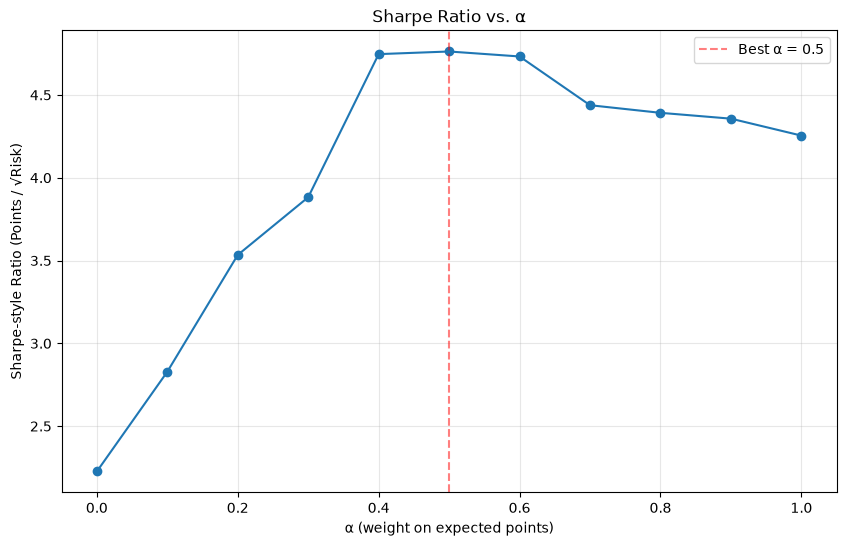

In [19]:
import matplotlib.pyplot as plt

alphas_plot = [r['alpha'] for r in results]
sharpe_plot = [r['sharpe'] for r in results]

plt.figure(figsize=(10, 6))
plt.plot(alphas_plot, sharpe_plot, marker='o')
plt.axvline(0.5, color='red', linestyle='--', alpha=0.5, label="Best α = 0.5")
plt.title('Sharpe Ratio vs. α')
plt.xlabel('α (weight on expected points)')
plt.ylabel('Sharpe-style Ratio (Points / √Risk)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Evaluating the Plot


The plot shows the Sharpe-style ratio for the 11 tested values of $\alpha$, with consecutive points joined by straight lines. It should therefore be interpreted as a sampled approximation of the underlying relationship between $\alpha$ and the Sharpe ratio, rather than the exact continuous curve.

Since $\alpha$ can take any value between 0 and 1, a finer grid would provide a higher-resolution approximation. However, the peak is already clearly visible around $\alpha=0.5$, with $\alpha=0.4$ producing a very similar value. A finer search would therefore be useful for locating the precise maximum, but is unlikely to materially change the conclusion from this initial grid search.

### Generating the Balanced Squad 

After evaluating all tested values of $\alpha$, we select the solution with the highest Sharpe-style ratio. The max() function identifies the result with the largest value of sharpe from the list of optimisation results.

We then report the corresponding $\alpha$, expected points, total risk, and Sharpe-style ratio. Finally, we display the selected starting XI, including each player's name, position, club, price, and points per game. Sorting by position makes the resulting formation easier to inspect.

This gives us the final balanced squad under the tested $\alpha$ values, selected according to the highest points-to-risk ratio rather than simply maximising expected points.

In [20]:
best = max(results, key=lambda r: r['sharpe'])
print(f"\nBest alpha by Sharpe-style ratio: {best['alpha']}")
print(f"Points: {best['total_points']:.1f}, Risk: {best['total_risk']:.1f}, Sharpe: {best['sharpe']:.3f}")
print(f"\nSelected XI:")
display(best['xi'][['web_name', 'position', 'club', 'now_cost', 'points_per_game']].sort_values('position'))


Best alpha by Sharpe-style ratio: 0.5
Points: 43.7, Risk: 84.3, Sharpe: 4.762

Selected XI:


,web_name,position,club,now_cost,points_per_game
137,Truffert,DEF,Bournemouth,48,4.3
188,Van den Berg,DEF,Brentford,44,3.5
231,Van Hecke,DEF,Brighton,47,4.1
779,Bowen,FWD,West Ham,78,4.9
838,Armstrong,FWD,Wolves,51,2.8
0,Raya,GK,Arsenal,62,4.4
173,Rayan,MID,Bournemouth,54,4.5
367,Garner,MID,Everton,52,4.2
433,Ampadu,MID,Leeds,49,3.8
634,Anderson,MID,Nott'm Forest,57,4.7


## Three-Way Comparison

With all three approaches now implemented, their performance can be compared using the same set of portfolio measures. This brings together the greedy baseline, the mean-variance formulation, and the balanced optimisation approach, providing directly comparable results for total points, risk, and the resulting Sharpe-style ratio. The three approaches can therefore be assessed side by side to answer the original question: can portfolio optimisation techniques improve FPL team selection compared to simple greedy-picking heuristics?

In [21]:
comparison = pd.DataFrame([
    {'Strategy': 'Greedy', 'Points': 42.9, 'Risk': 156.2, 'Sharpe': 3.434},
    {'Strategy': 'Mean-Variance', 'Points': 56.1, 'Risk': 170.8, 'Sharpe': 4.293},
    {'Strategy': 'Balanced (α=0.5)', 'Points': 43.7, 'Risk': 84.3, 'Sharpe': 4.762},
])
comparison = comparison.set_index('Strategy')
display(comparison)

,Points,Risk,Sharpe
Strategy,,,
Greedy,42.9,156.2,3.434
Mean-Variance,56.1,170.8,4.293
Balanced (α=0.5),43.7,84.3,4.762


## Findings

The original question was: "Can portfolio optimisation techniques improve FPL team selection compared to simple greedy-picking heuristics?"

The results provide a clear answer: yes. The greedy baseline produced a Sharpe-style ratio of 3.434, while both portfolio-optimised approaches achieved higher values. Objective 2 produced the highest expected points at 56.1, with a risk of 170.8 and a Sharpe-style ratio of 4.293. Objective 3 produced slightly fewer expected points at 43.7, but substantially reduced risk to 84.3, giving the highest Sharpe-style ratio of 4.762. Portfolio optimisation therefore improved on the greedy approach under both formulations, although the preferred strategy depends on whether the priority is maximising expected points or achieving the strongest risk-adjusted outcome.

The results also connect closely back to the MPT framework developed earlier. The efficient-frontier sweep showed that the best risk-adjusted outcome occurred at $\alpha=0.5$, rather than at $\alpha=1.0$, where the optimiser places all of its weight on expected points. This suggests that maximising expected points alone does not produce the strongest risk-adjusted portfolio. The final comparison reinforces this: Objective 2 prioritises higher expected points, while Objective 3 sacrifices some of this in exchange for a much lower level of risk and ultimately achieves the higher Sharpe-style ratio. In this sense, the results follow the central MPT idea that portfolio construction is not simply about selecting the assets with the highest expected returns, but about finding an appropriate balance between return and risk.

There are, however, several limitations to the model. Most importantly, the optimisation uses a diagonal-only risk approximation, meaning that although a full covariance matrix was estimated from the gameweek data, the off-diagonal covariance terms are not included in the objective function. The model therefore does not capture the true diversification benefit that motivated the MPT framework in the first place. The squad and starting XI are also optimised sequentially, with the squad selected first and the strongest valid XI then chosen from within it, rather than optimising both simultaneously. In addition, the 450-minute threshold used to define the active player pool is a practical judgement rather than a statistically derived cutoff, while the normalisation bounds used to scale expected points and risk in Objective 3 are also simplified proxies. These choices keep the model manageable and interpretable, but they mean the results should be viewed as an application of portfolio optimisation principles rather than a fully realistic FPL forecasting system.

The natural next step would therefore be to move towards a full covariance-aware objective, using a solver capable of handling the resulting quadratic optimisation problem. The squad and starting XI could also be optimised jointly, allowing the model to consider the complete team structure in a single optimisation. Beyond the formulation itself, the $\alpha$ sweep could be made more granular to examine the efficient frontier in greater detail, while testing the methodology on another FPL season would provide an out-of-sample check of whether the results generalise beyond the 2025–26 data used here. Together, these extensions would turn the current foundational model into a more rigorous test of whether portfolio optimisation can consistently improve FPL team selection.